# 01 · EDA: Ukrainian grade-5 math problems

Train 1,526 problems with answers, hints and typical errors; test 3,561 problems. 29 skills. Metric: exact match of the canonical answer.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
import warnings; warnings.filterwarnings("ignore")
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from hw4.data import load, load_split
IMG = Path.cwd().parent / "images"
RUNS = Path.cwd().parent / "runs"
pd.set_option("display.width", 140); pd.set_option("display.max_columns", 20); pd.set_option("display.max_colwidth", 90)
sns.set_theme(style="whitegrid", font_scale=0.9)

In [2]:
tr, te = load("train"), load("test")
print(tr.shape, te.shape)
tr.head(3)[["skill", "statement", "answer", "steps"]]

(1526, 8) (3561, 4)


,skill,statement,answer,steps
0,U-TIME,Переведи 10 год у хвилини.,600,[]
1,N-DIVTEST,"Скільки з чисел 372, 215, 894, 513, 244, 983, 318, 257 діляться на 2?",4,[]
2,N-DIVREM,Знайди остачу від ділення 54 на 5.,4,[10]


## Skills
The test split is stratified by skill like train, so the skill mix is the same (~2.3× more rows per skill).

In [3]:
cnt = pd.DataFrame({"train": tr.skill.value_counts(), "test": te.skill.value_counts()}).fillna(0).astype(int)
cnt["test/train"] = (cnt.test / cnt.train).round(2)
titles = dict(zip(tr.skill, tr.skill_title))
cnt["title"] = cnt.index.map(titles)
cnt.sort_values("train", ascending=False)

,train,test,test/train,title
skill,,,,
AVG,60,140,2.33,Середнє арифметичне
D-MUL10,60,140,2.33,"Множення й ділення десяткових на 10, 100, 1000"
D-SUB,60,139,2.32,Віднімання десяткових дробів
EQ-ADD-SUB,60,140,2.33,Рівняння: додавання й віднімання
N-ADD-MULTI,60,140,2.33,Додавання багатоцифрових чисел стовпчиком
N-ROUND,60,140,2.33,Округлення натуральних чисел
N-ORDER,60,140,2.33,Порядок дій у виразах з додаванням і множенням
WORD-2,60,140,2.33,Текстові задачі у дві дії
N-SUB-MULTI,60,140,2.33,Віднімання багатоцифрових чисел стовпчиком


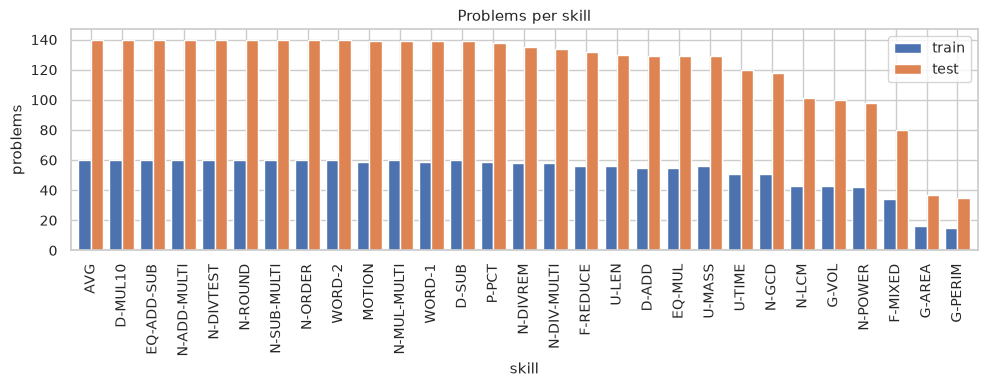

In [4]:
fig, ax = plt.subplots(figsize=(10, 4))
cnt.sort_values("test", ascending=False)[["train", "test"]].plot.bar(ax=ax, width=0.8)
ax.set_ylabel("problems"); ax.set_title("Problems per skill")
plt.tight_layout(); plt.savefig(IMG / "eda_skills.png", dpi=130); plt.show()

## Statements
Short, template-like problems: most are a single expression (`Обчисли: 867 + 244`), the rest are one- or two-step word problems.

In [5]:
for d, n in ((tr, "train"), (te, "test")):
    L = d.statement.str.len()
    print(f"{n}: chars median {L.median():.0f}, p90 {L.quantile(.9):.0f}, max {L.max()}; "
          f"with a decimal comma {d.statement.str.contains(r'\d,\d').mean():.1%}")
tr.groupby("skill").statement.apply(lambda s: s.str.len().median()).sort_values().tail(8)

train: chars median 31, p90 95, max 189; with a decimal comma 10.9%
test: chars median 31, p90 97, max 189; with a decimal comma 10.9%


skill
F-REDUCE      64.0
N-DIVTEST     69.0
P-PCT         84.0
WORD-1        87.0
G-VOL         92.0
MOTION        95.0
AVG          110.0
WORD-2       111.0
Name: statement, dtype: float64

## Answers and the canonical format
Integers dominate. A non-integer answer is a **decimal exactly when the statement contains a decimal number**, otherwise a reduced fraction (`207 : 10 → 207/10` but `1,012 : 1000 → 0.001012`). `hw4.answers.canonical` implements this rule; it reproduces every train answer.

In [6]:
kind = tr.answer.map(lambda a: "fraction" if "/" in a else "decimal" if "." in a else "integer")
display(pd.crosstab(tr.skill, kind).query("decimal > 0 or fraction > 0"))
from fractions import Fraction
from hw4.answers import canonical, extract_answer
bad = [(r.statement, r.answer) for r in tr.itertuples() if canonical(extract_answer("Відповідь: " + r.answer), r.statement) != r.answer]
print(kind.value_counts().to_dict(), "| format rule mismatches:", len(bad))

answer,decimal,fraction,integer
skill,,,
D-ADD,44,0,11
D-MUL10,32,8,20
D-SUB,60,0,0
F-MIXED,0,16,18


{'integer': 1366, 'decimal': 136, 'fraction': 24} | format rule mismatches: 0


In [7]:
num = tr.answer.map(lambda a: float(Fraction(a)))
print(num.describe().round(2).to_dict())
print("answers with >= 4 digits:", f"{(num.abs() >= 1000).mean():.1%}")

{'count': 1526.0, 'mean': 11376.87, 'std': 83127.98, 'min': 0.0, '25%': 12.0, '50%': 56.0, '75%': 520.0, 'max': 988300.0}
answers with >= 4 digits: 16.7%


## Steps, hints and typical errors
`steps` are intermediate values of multi-step problems; `typical_errors` list wrong answers with the misconception behind each, used later for error analysis and as DPO rejected answers.

In [8]:
tr["n_steps"] = tr.steps.map(len); tr["n_err"] = tr.typical_errors.map(len)
print(tr.n_steps.value_counts().sort_index().to_dict(), "| typical errors per problem:", tr.n_err.value_counts().sort_index().to_dict())
errs = pd.Series([e["id"] for es in tr.typical_errors for e in es]).value_counts()
errs.head(15)

{0: 798, 1: 664, 2: 64} | typical errors per problem: {1: 829, 2: 697}


wrong_direction                169
multiply_instead               110
add_instead                     92
wrong_zeros                     71
subtract_instead                61
forget_carry                    60
no_shift                        60
fraction_digits_as_integers     60
left_to_right                   60
first_step_only                 60
smaller_from_larger             60
forgot_divide                   60
divide_by_count_minus_one       60
skip_zero                       58
partial_reduce                  56
Name: count, dtype: int64

In [9]:
r = tr[tr.skill == "N-MUL-MULTI"].iloc[0]
print(r.statement, "=>", r.answer, "| steps", r.steps)
for h in r.hints: print("  hint:", h)
for e in r.typical_errors: print("  typical error:", e["value"], "-", e["id"])

Обчисли: 204 × 87 => 17748 | steps ['1428', '16320']
  hint: Ми множимо 204 на 87. Як ти множиш на двоцифрове число стовпчиком?
  hint: Помнож перше число спочатку на цифру одиниць множника, потім на цифру десятків. Отримаєш два часткові добутки.
  hint: Другий частковий добуток рахуємо на десятки, тому його записуємо на один розряд лівіше: у розряді одиниць цього рядка нічого не пишемо (там нуль). Потім додай обидва часткові добутки.
  typical error: 3060 - no_shift


## Validation split
Fixed for every comparison: 30% of train, stratified by skill, seed 42 (`hw4.data`). Few-shot examples and fine-tuning data come only from the other 70%.

In [10]:
va, trs = load_split("val"), load_split("train")
print(len(trs), "train side,", len(va), "val")
print("min / max val rows per skill:", va.skill.value_counts().min(), va.skill.value_counts().max())

1068 train side, 458 val
min / max val rows per skill: 4 18


## Synthetic problems
My own generators (`hw4.synth`) for all 29 skills with exact answers. Used only as training data (the teacher's solutions are kept when they reproduce the generated answer). Statements identical to a train or test statement are dropped.

In [11]:
syn = pd.read_json(RUNS / "data_synth" / "problems.jsonl", lines=True, dtype={"answer": str})
print(len(syn), "synthetic problems,", syn.skill.nunique(), "skills; overlap with train/test statements:",
      len(set(syn.statement) & (set(tr.statement) | set(te.statement))))
syn.groupby("skill").head(1).sample(8, random_state=0)[["skill", "statement", "answer"]]

8700 synthetic problems, 29 skills; overlap with train/test statements: 0


,skill,statement,answer
600,D-SUB,"Обчисли: 20,4 - 19,47",0.93
6000,N-ORDER,Обчисли: 9 × 2 + 138,156
6900,P-PCT,"Туристи пройшли 40% маршруту, і це 68 км. Яка довжина всього маршруту в кілометрах?",170
3900,N-SUB-MULTI,Обчисли: 707 - 184,523
3300,MOTION,Літак летить рівномірно й долає 4776 км за 6 год. Знайди швидкість руху в км/год.,796
7500,U-MASS,Запиши в грамах: 17 кг 873 г.,17873
8100,WORD-1,Один пакет містить 24 олівців. Придбали 12 пакетів. Скільки олівців придбали?,288
7800,U-TIME,Запиши в годинах: 52 доби 15 год.,1263
